In [21]:
print("Cluster Analysis")

Cluster Analysis


In [22]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [23]:
df = pd.read_csv("cleaned_semiconductor.csv")
feature_cols = [
    "pValenceElectrons_Mean",
    "Electronegativity_Mean",
    "MeltingPoint_Mean",
    "AtomicWeight_Mean",
    "CovalentRadius_Mean",
    "SpaceGroupNumber_Mean",
]
X = df[feature_cols]

In [24]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [25]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(X_scaled)

In [26]:
df["Cluster"] = cluster_labels
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=feature_cols)
print("\nCluster centroids (standardized):")
print(centroids.round(3))



Cluster centroids (standardized):
   pValenceElectrons_Mean  Electronegativity_Mean  MeltingPoint_Mean  \
0                  -1.116                  -1.023              0.599   
1                   0.847                   1.368             -0.718   
2                  -1.013                  -0.703              1.151   
3                   0.570                  -0.012             -0.473   

   AtomicWeight_Mean  CovalentRadius_Mean  SpaceGroupNumber_Mean  
0              1.251                1.255                  0.938  
1             -0.919               -1.290                 -1.001  
2             -0.359                0.113                  1.125  
3              0.196                0.178                 -0.437  


In [27]:
bandgap_by_cluster = df.groupby("Cluster")["BandGap_eV"].agg(["mean", "median", "count"])
print("\nBandGap_eV by cluster:")
print(bandgap_by_cluster.round(3))


BandGap_eV by cluster:
          mean  median  count
Cluster                      
0        0.142     0.0    850
1        1.647     0.0   1140
2        0.212     0.0    952
3        1.380     1.4   1662



Variance explained by 2 PCA components: 83.1%

Saved plot to kmeans_semiconductor.png


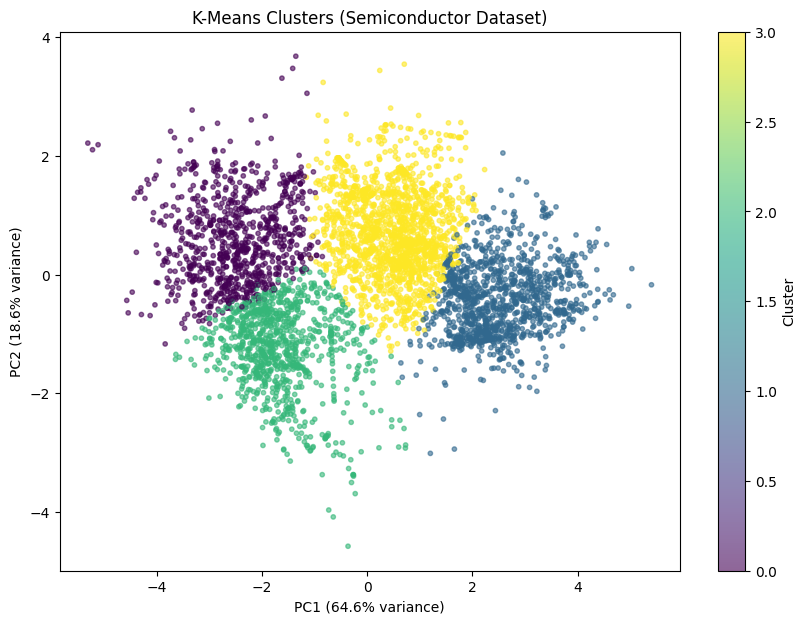

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(f"\nVariance explained by 2 PCA components: {pca.explained_variance_ratio_.sum():.1%}")
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap="viridis", s=10, alpha=0.6)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title("K-Means Clusters (Semiconductor Dataset)")
plt.colorbar(scatter, label="Cluster")
plt.savefig("kmeans_semiconductor.png", dpi=150, bbox_inches="tight")
print("\nSaved plot to kmeans_semiconductor.png")